In [ ]:
from google.colab import files
import zipfile
# Step 1: Upload zip file
uploaded = files.upload()

Saving eyesdiseaseds.zip to eyesdiseaseds.zip


In [ ]:
# Step 2: Unzip it
zip_path = "eyesdiseaseds.zip"  # Change to your uploaded filename
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
import os
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

In [ ]:
base_path = "/content/dataset/training data"

diseased_folder = os.path.join(base_path, "aug_disesed")
healthy_folder = os.path.join(base_path, "healthy")

print("Diseased folder:", os.path.exists(diseased_folder))
print("Healthy folder:", os.path.exists(healthy_folder))

Diseased folder: True
Healthy folder: True


In [ ]:
def load_images_from_folder(folder, label, img_size=(150, 150)):
    data = []

    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        img = cv2.imread(path)

        if img is not None:
            img = cv2.resize(img, img_size)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            data.append((img, label))

    return data


diseased_data = load_images_from_folder(diseased_folder, 0)
healthy_data = load_images_from_folder(healthy_folder, 1)

data = diseased_data + healthy_data
np.random.shuffle(data)

X = np.array([item[0] for item in data], dtype=np.float32) / 255.0
y = np.array([item[1] for item in data], dtype=np.int32)

print("Total images:", len(X))
print("Diseased images:", len(diseased_data))
print("Healthy images:", len(healthy_data))
print("X shape:", X.shape)
print("y shape:", y.shape)

Total images: 1744
Diseased images: 900
Healthy images: 844
X shape: (1744, 150, 150, 3)
y shape: (1744,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 1395
Testing images: 349


In [ ]:
model = Sequential([
    tf.keras.Input(shape=(150, 150, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=42,
    validation_split=0.2
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 23s 343ms/step - accuracy: 0.8351 - loss: 0.4054 - val_accuracy: 0.9677 - val_loss: 0.1313
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9758 - loss: 0.0929 - val_accuracy: 0.9606 - val_loss: 0.1209
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9892 - loss: 0.0497 - val_accuracy: 0.9857 - val_loss: 0.0559
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9901 - loss: 0.0439 - val_accuracy: 0.9892 - val_loss: 0.0352
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9875 - loss: 0.0487 - val_accuracy: 0.9785 - val_loss: 0.0527
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9901 - loss: 0.0375 - val_accuracy: 0.9892 - val_loss: 0.0307
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9901 - loss: 0.0306 - val_accuracy: 0.9857 - val_loss: 0.0628
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9857 - loss: 0.0451 - val_accuracy: 0.9642 -

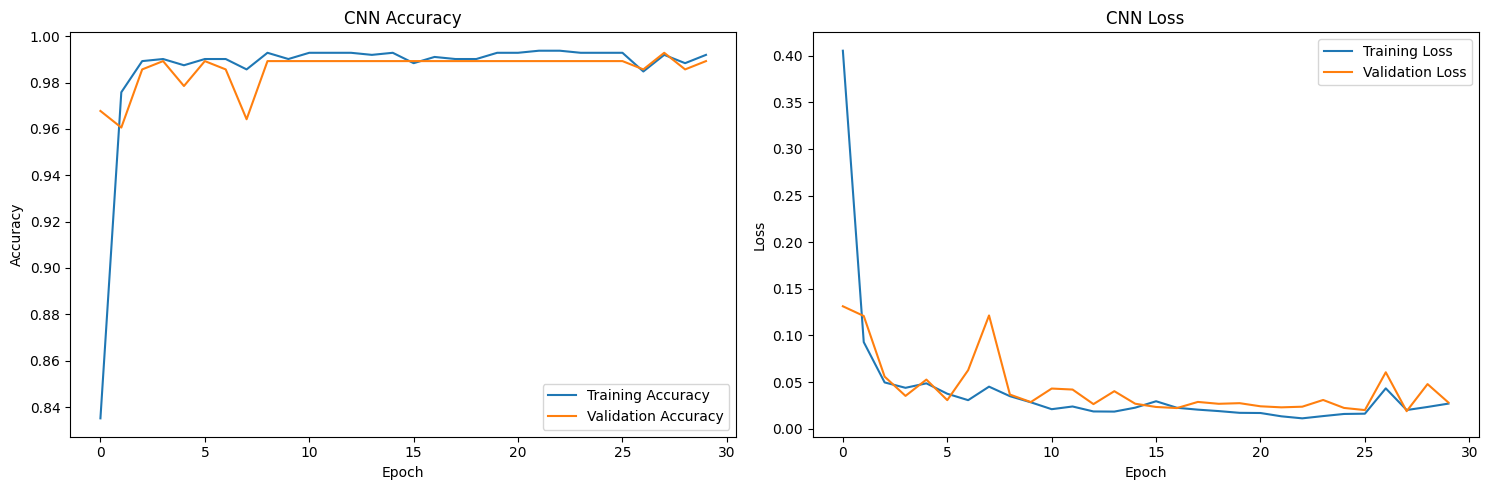

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.0227
Test Accuracy: 98.85 %


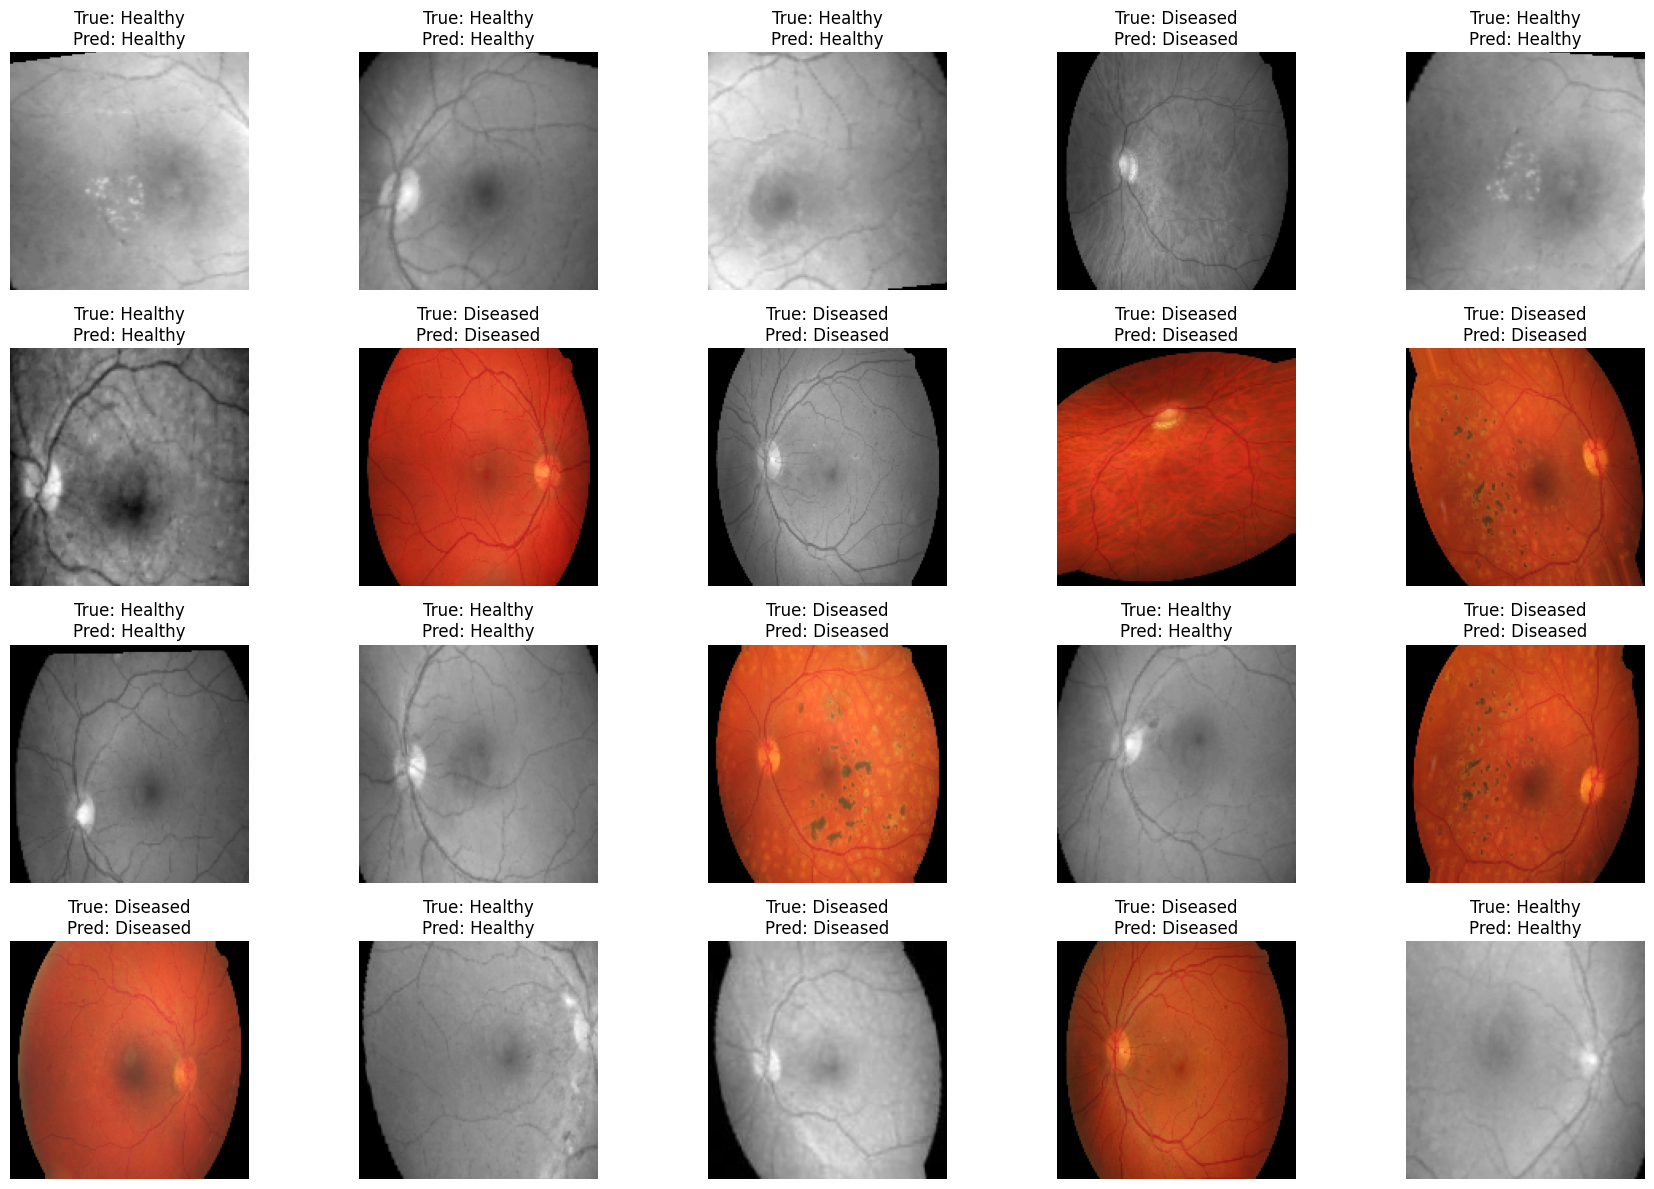

In [ ]:
class_names = ["Diseased", "Healthy"]

indices = np.random.choice(
    len(X_test),
    size=min(20, len(X_test)),
    replace=False
)

plt.figure(figsize=(18, 12))

for i, idx in enumerate(indices):
    img = X_test[idx]
    true_label = int(y_test[idx])

    pred_prob = model.predict(
        img.reshape(1, 150, 150, 3),
        verbose=0
    )[0][0]

    pred_label = 1 if pred_prob >= 0.5 else 0

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.axis('off')

    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}"
    )

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

files.download("/content/cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save("/content/cnn_model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!
